
### __Site-based Dataset Loading__

- This notebook uses the dataset that has already been split by recording site. Each split corresponds to one recording site, for example `train_A`, `validation_A`, and `test_A`.

- This allows us to train and validate on one site, then test on all selected sites.

In [20]:
import os
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from datetime import datetime
from datasets import DatasetDict, load_from_disk
from torch.utils.data import DataLoader

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Remember to restart kernel after each run


### __Part I : Data Preparation__


In [21]:
site_subsets = load_from_disk("../dataset/mel_by_site/PD1_phone_mel_site_subsets_encoded")
# site_subsets = load_from_disk("../dataset/mfcc_by_site/PD1_phone_mfcc_site_subsets_encoded")

In [22]:
print(site_subsets)

DatasetDict({
    train_A: Dataset({
        features: ['feat', 'frame_index', 'utt_id', 'speaker_uid', 'volume', 'speaker_id', 'recording_site', 'sex', 'age', 'pd2', 'phones', 'label'],
        num_rows: 1319069
    })
    validation_A: Dataset({
        features: ['feat', 'frame_index', 'utt_id', 'speaker_uid', 'volume', 'speaker_id', 'recording_site', 'sex', 'age', 'pd2', 'phones', 'label'],
        num_rows: 215391
    })
    test_A: Dataset({
        features: ['feat', 'frame_index', 'utt_id', 'speaker_uid', 'volume', 'speaker_id', 'recording_site', 'sex', 'age', 'pd2', 'phones', 'label'],
        num_rows: 216520
    })
    train_N: Dataset({
        features: ['feat', 'frame_index', 'utt_id', 'speaker_uid', 'volume', 'speaker_id', 'recording_site', 'sex', 'age', 'pd2', 'phones', 'label'],
        num_rows: 1086887
    })
    validation_N: Dataset({
        features: ['feat', 'frame_index', 'utt_id', 'speaker_uid', 'volume', 'speaker_id', 'recording_site', 'sex', 'age', 'pd2', 'p

- Here, we choose the recording site used for both training and validation.
    
- The trained model will then be evaluated on all sites listed in `test_sites`.

- This setup is used to examine within-site and cross-site transfer.

In [23]:
recording_sites = {
    "A": "Kiel",
    "N": "Bonn",
    "D": "Munich",
}

# choose which recording site to train and validate on
# train_site = "A"
# train_site = "N"
train_site = "D"

test_sites = ["A", "N", "D"] # range of the test sites

if train_site not in recording_sites:
    raise ValueError(f"Unknown train_site: {train_site}")

In [24]:
# initializing the parameters
batch_size_train = 256
batch_size_eval = 256

num_hidden=50
learning_rate = 0.001
EPOCHS = 8

seed = 42

In [25]:
# set random seeds to make the experiment more reproducible
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

In [26]:
# selects the available computing device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)

Device: mps


- The model is trained and validated on the `same recording site`.

- `Test` sets are not included here, because they will be loaded separately for each test site later.

In [27]:
# combine the selected site specific train and validation splits
ds_dict = DatasetDict({
    "train": site_subsets[f"train_{train_site}"],
    "validation": site_subsets[f"validation_{train_site}"],
})

print(ds_dict)
print(ds_dict["validation"][2])

DatasetDict({
    train: Dataset({
        features: ['feat', 'frame_index', 'utt_id', 'speaker_uid', 'volume', 'speaker_id', 'recording_site', 'sex', 'age', 'pd2', 'phones', 'label'],
        num_rows: 1660646
    })
    validation: Dataset({
        features: ['feat', 'frame_index', 'utt_id', 'speaker_uid', 'volume', 'speaker_id', 'recording_site', 'sex', 'age', 'pd2', 'phones', 'label'],
        num_rows: 145435
    })
})
{'feat': [3.22448e-05, 8.3107e-06, 1.036e-07, 9.49e-08, 5.3e-08, 1.04e-07, 7.11e-08, 1.69e-08, 1.45e-08, 8.5e-09, 1.17e-08, 7.8e-09, 1.8e-08, 2.2e-08, 3.14e-08, 4.22e-08, 1.73e-08, 9.6e-09, 1.62e-08, 5.5e-09, 4.5e-09, 1.61e-08, 8e-09, 1.08e-08, 1.01e-08, 5.2e-09, 8.3e-09, 1e-08, 7.8e-09, 8.7e-09, 1.01e-08, 8.3e-09], 'frame_index': 2, 'utt_id': 'bied1070', 'speaker_uid': 'BIED', 'volume': '2', 'speaker_id': 'BIE', 'recording_site': 'D', 'sex': 'W', 'age': 'A', 'pd2': '', 'phones': '<p:>', 'label': 3}


In [28]:
label_feature = ds_dict["train"].features["label"]
num_feat = len(ds_dict["train"][0]["feat"])

num_classes = label_feature.num_classes
phone_names = label_feature.names

print("Feature dimension:", num_feat)
print("Number of phone classes:", num_classes)
print("Phone names:", phone_names)

Feature dimension: 32
Number of phone classes: 44
Phone names: ['2:', '6', '9', '<p:>', '?', '@', 'C', 'E', 'E:', 'I', 'N', 'O', 'OY', 'S', 'U', 'Y', 'Z', 'a', 'a:', 'aI', 'aU', 'a~', 'b', 'd', 'e:', 'f', 'g', 'h', 'i:', 'j', 'k', 'l', 'm', 'n', 'o:', 'p', 'r', 's', 't', 'u:', 'v', 'x', 'y:', 'z']


In [29]:
# convert selected columns to PyTorch tensors
ds_dict = ds_dict.with_format(type="torch", columns=["feat", "label"])

In [30]:
loader_generator = torch.Generator()
loader_generator.manual_seed(seed) # make sure the reproducability of the project

training_loader = torch.utils.data.DataLoader(
    ds_dict["train"],
    batch_size=batch_size_train,
    shuffle=True, generator=loader_generator
)

validation_loader = torch.utils.data.DataLoader(
    ds_dict["validation"],
    batch_size=batch_size_eval,
    shuffle=False
)

### __Part II : MLP Model__

- We use a simple multi-layer perceptron for frame-level phone classification.

- The model takes one feature vector as input and predicts one phone class.

- It has one hidden layer with ReLU activation, one hidden layer makes predictions to n_classes.

In [31]:
class MLP(nn.Module):
    def __init__(self, num_feat, num_classes, num_hidden):
        super().__init__()
        self.fc1 = nn.Linear(num_feat, num_hidden)
        self.fc2 = nn.Linear(num_hidden, num_classes)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

In [32]:
# initialize model, loss function, and optimizer
torch.manual_seed(seed)

model = MLP(num_feat=num_feat, num_classes=num_classes, num_hidden=num_hidden).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

print(model)

MLP(
  (fc1): Linear(in_features=32, out_features=50, bias=True)
  (fc2): Linear(in_features=50, out_features=44, bias=True)
)


In [33]:
def train_one_epoch():
    model.train() # this MLP is without dropout, but still we add the model.train() here

    total_loss = 0.0 # total loss in this epoch
    total_samples = 0 # how many samples are trained in this epoch

    for batch_index, data in enumerate(training_loader):
        inputs = data["feat"].to(device=device, dtype=torch.float32) # get mel feature

        labels = data["label"].to(device=device, dtype=torch.long) 

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

        # weight the batch loss by batch size, because the last batch may be smaller
        current_batch_size = labels.size(0)
        total_loss += (loss.item() * current_batch_size)

        total_samples += current_batch_size

        if (batch_index + 1) % 100 == 0:
            print(f"Batch {batch_index + 1}: loss = {loss.item():.4f}")

    average_loss = total_loss / total_samples
    
    return average_loss

In [34]:
def validate():
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for data in validation_loader:
            inputs = data["feat"].to(device=device, dtype=torch.float32)

            labels = data["label"].to(device=device, dtype=torch.long)

            outputs = model(inputs)
            loss = loss_fn(outputs, labels)

            predictions = outputs.argmax(dim=1)

            current_batch_size = labels.size(0)

            total_loss += (loss.item() * current_batch_size)

            total_correct += (predictions == labels).sum().item()

            total_samples += current_batch_size

    average_loss = total_loss / total_samples

    accuracy = total_correct / total_samples

    return average_loss, accuracy

- The output folder name includes the training site.

- This keeps site-specific experiments separate, for example models trained on A, N, or D.

In [35]:
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

models_save_dir = "../model_for_mel_by_sites/models"
# models_save_dir = "../model_for_mfcc_by_sites/models"

model_name = f"mel_train_site_{train_site}_{timestamp}"
# model_name = f"mfcc_train_site_{train_site}_{timestamp}"

model_directory = os.path.join(models_save_dir, model_name)

os.makedirs(model_directory, exist_ok=False)

best_model_path = os.path.join(model_directory,"best_vloss.pt") # save model with lowest val loss

#### This is the main training loop.
- After each epoch, the model is evaluated on the validation set.

- The checkpoint with the lowest validation loss is saved as the best model.

In [36]:
best_vloss = float("inf") # must be bigger than the first loss

history = {"train_loss": [], "validation_loss": [], "validation_accuracy": [],}

for epoch in range(EPOCHS):
    print(f"\nEPOCH {epoch + 1}/{EPOCHS}")

    average_train_loss = train_one_epoch()

    average_validation_loss, validation_accuracy = validate()

    history["train_loss"].append(average_train_loss)

    history["validation_loss"].append(average_validation_loss)

    history["validation_accuracy"].append(validation_accuracy)

    print(f"Train loss: {average_train_loss:.4f}")

    print(f"Validation loss: {average_validation_loss:.4f}")

    print(f"Validation accuracy: {validation_accuracy:.4f}")

    if average_validation_loss < best_vloss:
        best_vloss = average_validation_loss

        torch.save(
            {"epoch": epoch + 1,
             "model_state_dict": model.state_dict(),
             "num_feat": num_feat,
             "num_classes": num_classes,
             "num_hidden": num_hidden,
             "phone_names": phone_names,
             "train_site": train_site,
             "train_site_name": recording_sites[train_site],
             "validation_loss": average_validation_loss,
             "validation_accuracy": validation_accuracy
             }, best_model_path)

        print(f"Best model saved at epoch {epoch + 1}.")


EPOCH 1/8
Batch 100: loss = 3.0830
Batch 200: loss = 2.2015
Batch 300: loss = 1.7925
Batch 400: loss = 1.8191
Batch 500: loss = 1.9601
Batch 600: loss = 1.8881
Batch 700: loss = 1.7663
Batch 800: loss = 1.8829
Batch 900: loss = 1.7397
Batch 1000: loss = 1.8247
Batch 1100: loss = 1.8305
Batch 1200: loss = 1.8394
Batch 1300: loss = 1.7156
Batch 1400: loss = 1.8625
Batch 1500: loss = 1.7695
Batch 1600: loss = 1.6938
Batch 1700: loss = 1.5578
Batch 1800: loss = 1.6932
Batch 1900: loss = 1.9306
Batch 2000: loss = 1.6085
Batch 2100: loss = 1.7917
Batch 2200: loss = 1.6584
Batch 2300: loss = 1.5302
Batch 2400: loss = 1.8116
Batch 2500: loss = 1.4516
Batch 2600: loss = 1.5866
Batch 2700: loss = 1.7199
Batch 2800: loss = 1.5863
Batch 2900: loss = 1.8014
Batch 3000: loss = 1.8139
Batch 3100: loss = 1.6295
Batch 3200: loss = 1.6250
Batch 3300: loss = 1.7960
Batch 3400: loss = 1.6605
Batch 3500: loss = 1.6598
Batch 3600: loss = 1.6615
Batch 3700: loss = 1.6349
Batch 3800: loss = 1.6693
Batch 3900

- After training, we load the best checkpoint according to validation loss.

- Reason: This ensures that the test evaluation uses the best validation model, not necessarily the model from the final epoch.

In [38]:
checkpoint = torch.load(best_model_path, map_location=device)

best_epoch = checkpoint["epoch"]
num_feat = checkpoint["num_feat"]
num_classes = checkpoint["num_classes"]
num_hidden = checkpoint["num_hidden"]
phone_names = checkpoint["phone_names"]
train_site = checkpoint["train_site"]

model = MLP(num_feat=num_feat, num_classes=num_classes, num_hidden=num_hidden).to(device)
model.load_state_dict(checkpoint["model_state_dict"]) # load the parameters
model.eval()

print("Best model loaded.")
print("Best epoch:", best_epoch)
print("Best validation loss:", checkpoint["validation_loss"])
print("Validation accuracy at best epoch:", checkpoint["validation_accuracy"])
print("Training Site:", train_site)

Best model loaded.
Best epoch: 8
Best validation loss: 1.3086066447736047
Validation accuracy at best epoch: 0.6515350500223468
Training Site: D



- This function evaluates the trained model on a given test DataLoader. Since we test the same model on multiple recording sites, the test loader is passed as an argument.

- The function returns both test accuracy and the confusion matrix for that specific test site.

In [26]:
def test_model(test_loader):
    model.eval()

    total_correct = 0
    total_samples = 0

    confusion_matrix = torch.zeros((num_classes, num_classes), dtype=torch.long)

    with torch.no_grad():
        for data in test_loader:
            inputs = data["feat"].to(device=device, dtype=torch.float32)
            labels = data["label"].to(device=device, dtype=torch.long)

            outputs = model(inputs)
            predictions = outputs.argmax(dim=1)

            total_correct += (predictions == labels).sum().item()
            total_samples += labels.size(0)

            # move to cpu, condusion matrix on cpu
            true_labels = labels.cpu()
            predicted_labels = (predictions.cpu())

            # we want to count: cm[true_label, predicted_label] += 1
            # torch.bincount works on 1D tensors, so we encode each 2D
            # (true_label, predicted_label) pair as one unique integer
            # if the integers are the same, that means they are in the same position in the confusion matrix
            combined = (true_labels * num_classes + predicted_labels)

            # count
            batch_confusion = torch.bincount(combined, minlength=(num_classes * num_classes)).reshape(num_classes, num_classes)
            confusion_matrix += batch_confusion

    test_accuracy = total_correct / total_samples

    return test_accuracy, confusion_matrix

In [28]:
site_test_results = {}

for test_site in test_sites:
    test_dataset = site_subsets[f"test_{test_site}"]

    test_dataset = test_dataset.with_format(type="torch", columns=["feat", "label"])

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size_eval,
        shuffle=False
    )

    test_accuracy, confusion_matrix = test_model(test_loader)

    site_test_results[test_site] = {
        "test_site": test_site,
        "test_site_name": recording_sites[test_site],
        "test_accuracy": test_accuracy,
        "num_test_samples": len(test_dataset),
        "confusion_matrix": confusion_matrix,
    }

    print(
        f"Train on {train_site} ({recording_sites[train_site]}), "
        f"validate on {train_site}, "
        f"test on {test_site} ({recording_sites[test_site]}): "
        f"{test_accuracy:.4f}"
    )

Train on D (Munich), validate on D, test on A (Kiel): 0.5522
Train on D (Munich), validate on D, test on N (Bonn): 0.5456
Train on D (Munich), validate on D, test on D (Munich): 0.6082


- This section saves the main experiment results.

- The JSON file stores model settings, dataset sizes, best validation metrics, test accuracy and training history.

- The confusion matrix is saved separately as a PyTorch tensor.

In [29]:
results = {
    "train_site": train_site,
    "train_site_name": recording_sites[train_site],
    "validation_site": train_site,
    "validation_site_name": recording_sites[train_site],
    "best_epoch": best_epoch,
    "best_validation_loss": checkpoint["validation_loss"],
    "best_validation_accuracy": checkpoint["validation_accuracy"],
    "site_test_results": {
        test_site: {
            "test_site_name": result["test_site_name"],
            "test_accuracy": result["test_accuracy"],
            "num_test_samples": result["num_test_samples"],
        }
        for test_site, result in site_test_results.items()
    },
    "num_train_samples": len(ds_dict["train"]),
    "num_validation_samples": len(ds_dict["validation"]),
    "num_feat": num_feat,
    "num_classes": num_classes,
    "num_hidden": num_hidden,
    "learning_rate": learning_rate,
    "epochs": EPOCHS,
    "batch_size_train": batch_size_train,
    "batch_size_eval": batch_size_eval,
    "history": history,
}

In [30]:
results_path = os.path.join(model_directory, "results.json")

with open(results_path, "w", encoding="utf-8") as file:
    json.dump(results, file, ensure_ascii=False, indent=2)

for test_site, result in site_test_results.items():
    confusion_matrix_path = os.path.join(
        model_directory,
        f"confusion_matrix_test_{test_site}.pt"
    )

    torch.save(result["confusion_matrix"], confusion_matrix_path)

#### Remember to restart kernel after each run

### __Part III : Evaluation analysis__

- In this part, we analyze the confusion matrix and the data we get from evaluation.

- We calculate per-phone recall and precision. We also save plots and CSV files for later comparison.

What's new?
- The model has been tested on multiple recording sites.

- We choose one test site for detailed confusion matrix analysis.

- To analyze another site, change `analysis_test_site` and rerun Part III.

In [60]:
# double check the test accuracy using the confusion matrix
# analysis_test_site = "A"
# analysis_test_site = "N"
analysis_test_site = "D"

test_accuracy = site_test_results[analysis_test_site]["test_accuracy"]
confusion_matrix = site_test_results[analysis_test_site]["confusion_matrix"]

evaluation_directory = os.path.join(model_directory, f"evaluation_test_{analysis_test_site}")
os.makedirs(evaluation_directory, exist_ok=True)

cm = confusion_matrix.cpu().numpy()

accuracy_from_cm = np.trace(cm) / cm.sum()

print(f"Global test accuracy: {test_accuracy:.4f}")
print(f"Accuracy calculated from confusion matrix: {accuracy_from_cm:.4f}")

assert np.isclose(test_accuracy, accuracy_from_cm)

Global test accuracy: 0.6082
Accuracy calculated from confusion matrix: 0.6082


- Recall means: among all frames with the specific true label, how many were correctly predicted.

- Precision means: among all frames predicted as the specific phone, how many were actually that phone.

- This gives a more detailed view than global accuracy.

In [61]:
# confusion matrix shape: [true label, predicted label]
true_support = cm.sum(axis=1) # get the total number of frames for each gold phone
predicted_support = cm.sum(axis=0) # get the total number of frames predicted as each phone

distribution_df = pd.DataFrame({
    "phone": phone_names,
    "true_sum": true_support,
    "true_percentage": true_support / cm.sum() * 100,
    "predicted_sum": predicted_support,
    "predicted_percentage": predicted_support / cm.sum() * 100,
    "correct_predictions": np.diag(cm) # extract the diagonal of the confusion matrix
})

# sort in descending order by true_sum
distribution_df = distribution_df.sort_values("true_sum", ascending=False)

distribution_df["recall"] = np.divide(
    distribution_df["correct_predictions"],
    distribution_df["true_sum"],
    out=np.zeros(len(distribution_df), dtype=float),
    where=distribution_df["true_sum"] != 0
)

distribution_df["precision"] = np.divide(
    distribution_df["correct_predictions"],
    distribution_df["predicted_sum"],
    out=np.zeros(len(distribution_df), dtype=float),
    where=distribution_df["predicted_sum"] != 0
)

print(distribution_df.head(15).to_string(index=False))

phone  true_sum  true_percentage  predicted_sum  predicted_percentage  correct_predictions   recall  precision
 <p:>    170279        44.537063         201325             52.657252               168926 0.992054   0.839071
    n     18967         4.960885          45365             11.865373                15135 0.797965   0.333627
    t     16503         4.316417          11918              3.117194                 2181 0.132158   0.183001
    6     12181         3.185983          14611              3.821558                 4242 0.348247   0.290329
    @     11110         2.905859          11677              3.054160                 2888 0.259946   0.247324
    s      9493         2.482927          11491              3.005511                 6849 0.721479   0.596032
   aI      8986         2.350319           6599              1.725991                 2980 0.331627   0.451584
   e:      7584         1.983622           7311              1.912217                 3049 0.402031   0.417043
 

- This heatmap shows the raw confusion matrix.

- Rows are true phone labels, and columns are predicted phone labels.

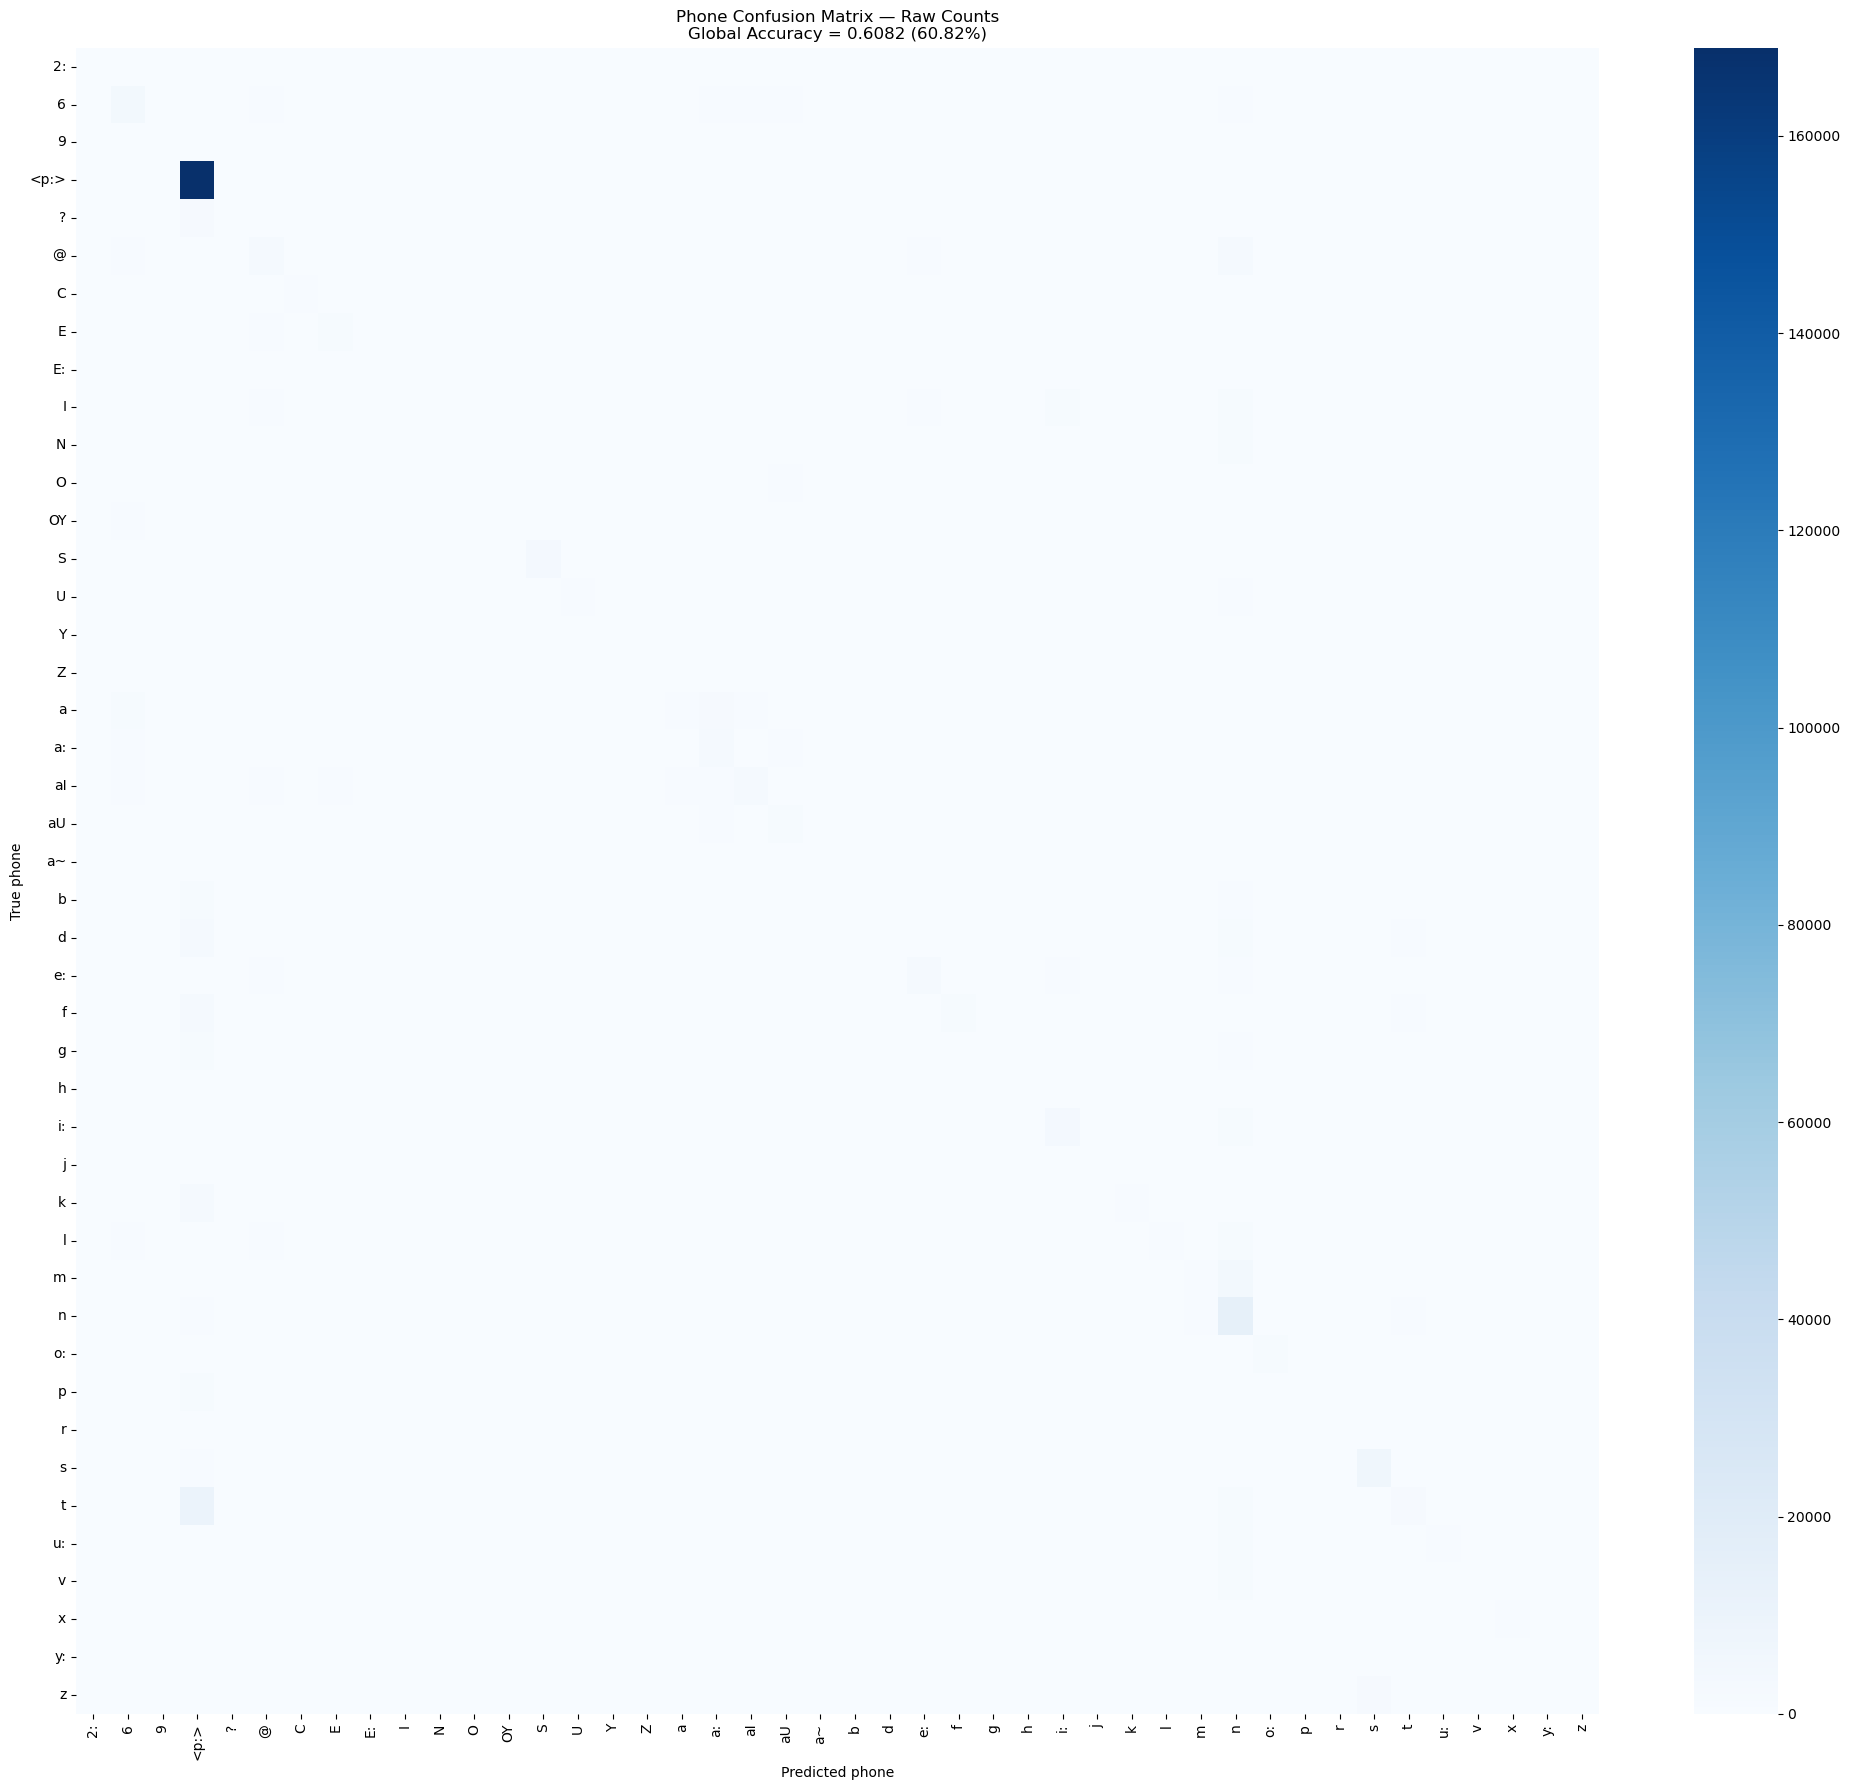

In [62]:
# plot the raw confusion matrix as a heatmap and save it as a png image
# the matrix here is not normalized, so the value in each cell represents the actual number of frames
plt.figure(figsize=(20, 18))

sns.heatmap(cm, xticklabels=phone_names, yticklabels=phone_names, cmap="Blues", annot=False)

# cm[true_phone_id, predicted_phone_id]
plt.xlabel("Predicted phone")
plt.ylabel("True phone")
plt.title(
    f"Phone Confusion Matrix — Raw Counts\n"
    f"Global Accuracy = {test_accuracy:.4f} "
    f"({test_accuracy * 100:.2f}%)"
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

raw_cm_path = os.path.join(evaluation_directory, "confusion_matrix_raw.png")

plt.savefig(raw_cm_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

- This heatmap shows the row-normalized confusion matrix.

- Each row sums to 1, so the values show the prediction distribution for each true phone.

- This makes it easier to compare phones with different numbers of test frames.

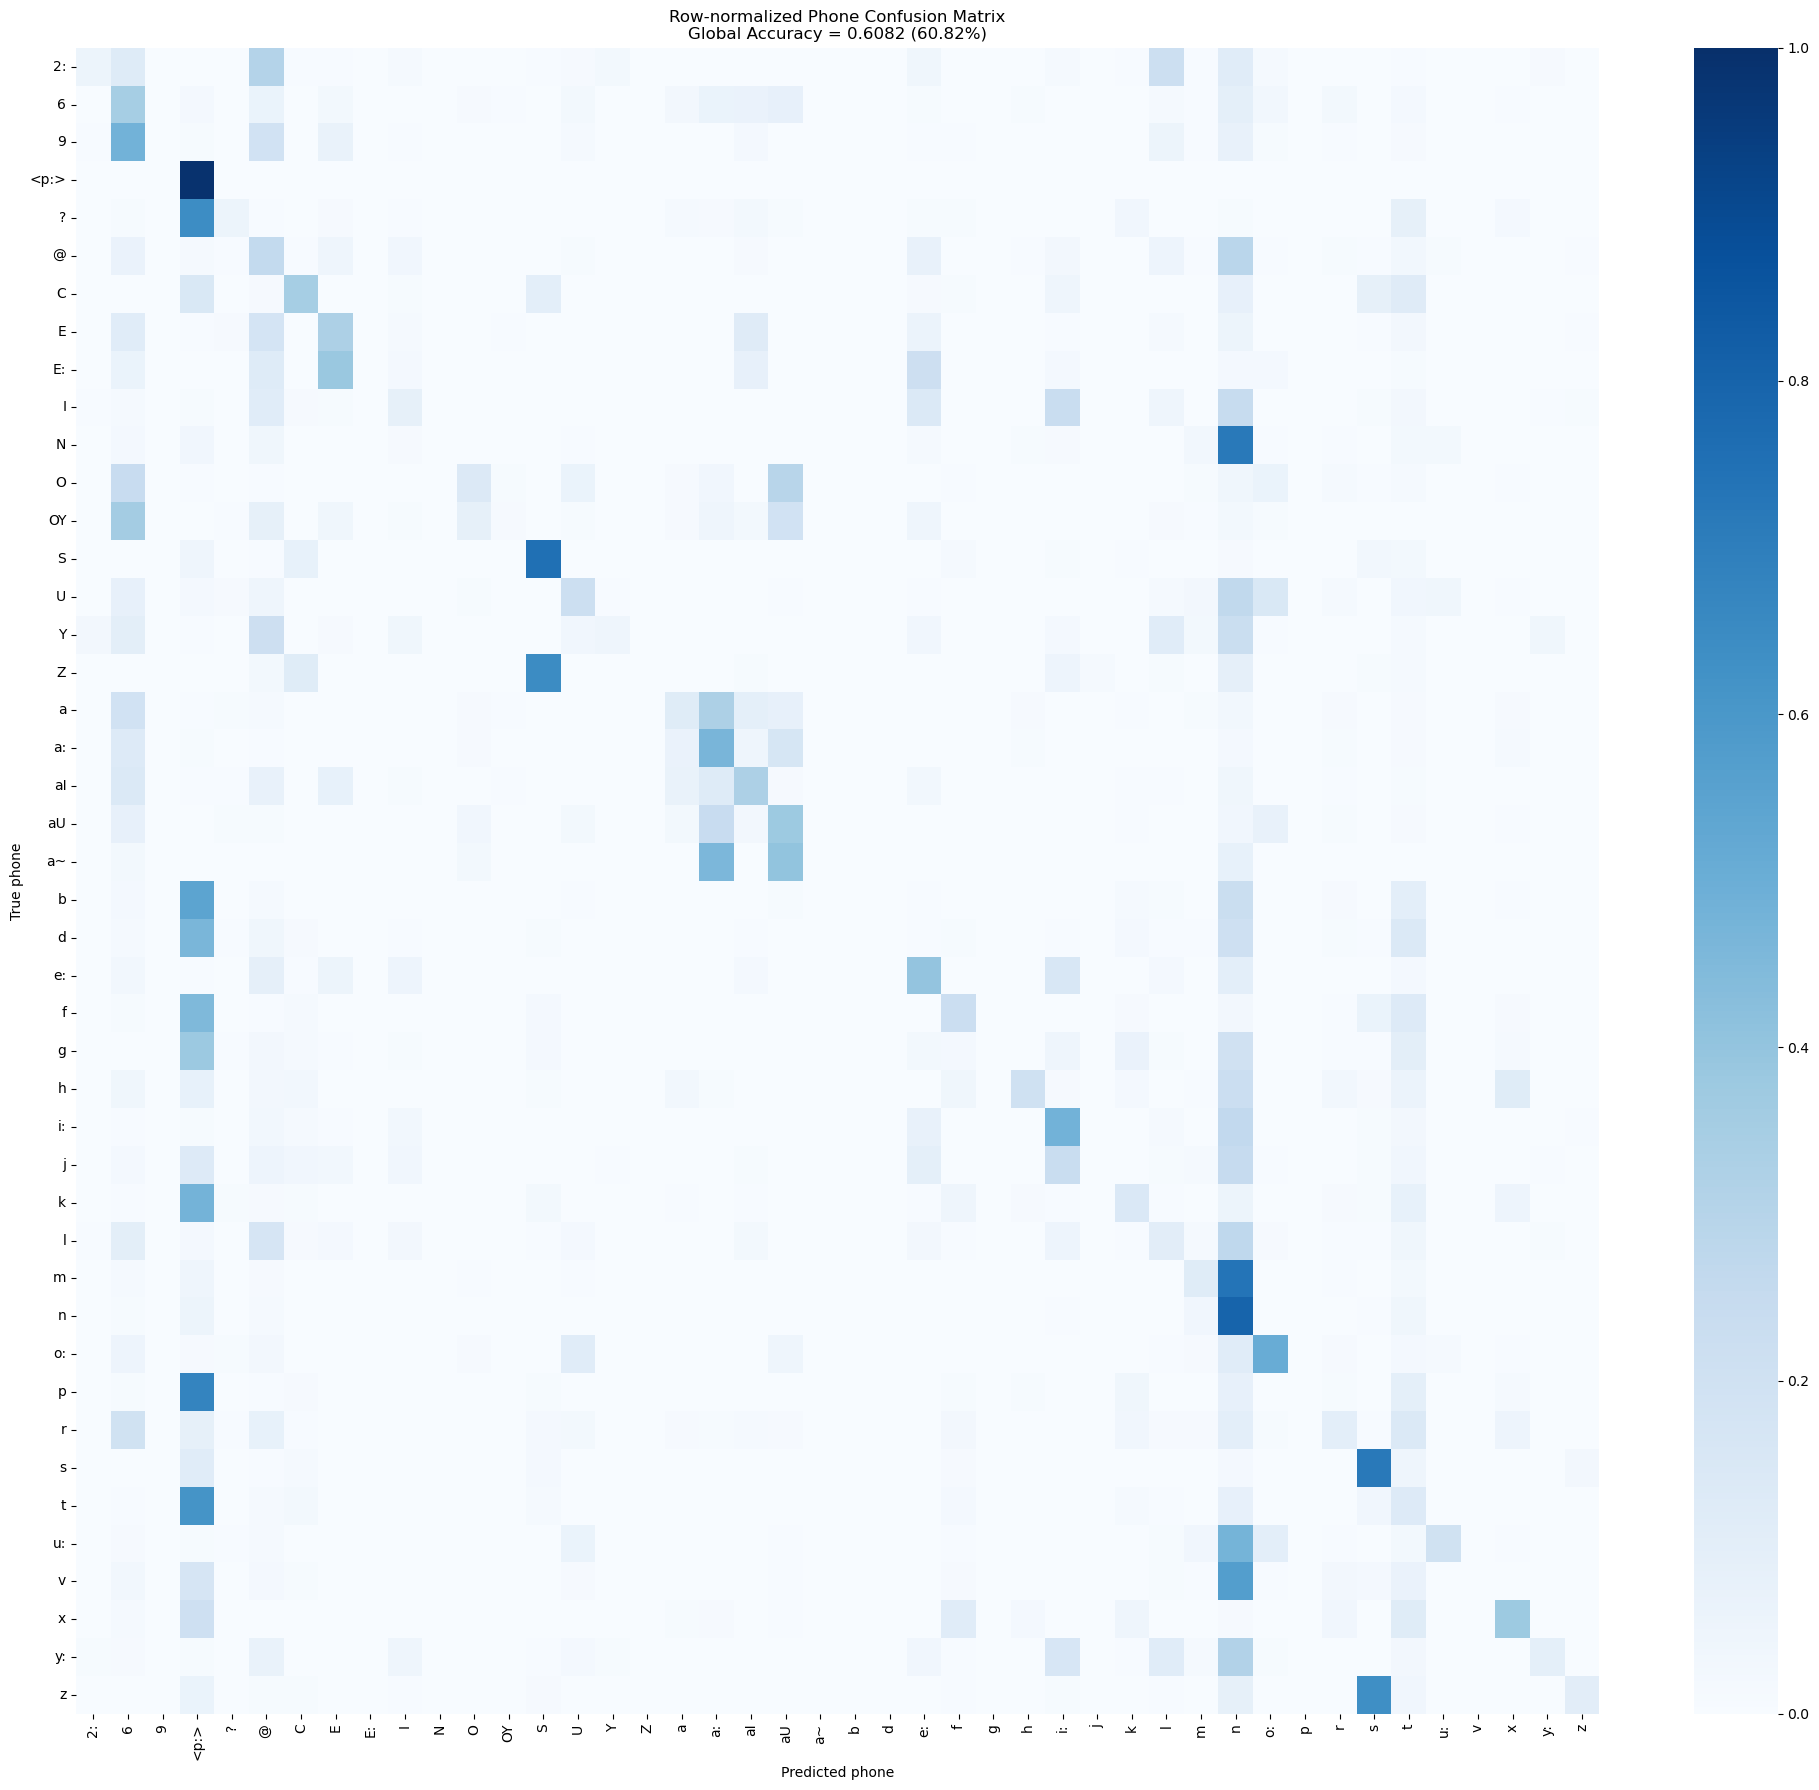

In [63]:
# normalize the raw confusion matrix row-wise based on the golden label
# then plot the normalized heatmap
row_totals = cm.sum(axis=1, keepdims=True) # (num_classes, 1)

cm_normalized = np.divide(cm, row_totals, out=np.zeros_like(cm, dtype=np.float64), where=(row_totals != 0))

plt.figure(figsize=(20, 18))

# do not display numbers in each cell, values from 0 to 1
sns.heatmap(cm_normalized, xticklabels=phone_names, yticklabels=phone_names, 
            cmap="Blues", vmin=0, vmax=1, annot=False)

plt.xlabel("Predicted phone")
plt.ylabel("True phone")
plt.title(
    f"Row-normalized Phone Confusion Matrix\n"
    f"Global Accuracy = {test_accuracy:.4f} "
    f"({test_accuracy * 100:.2f}%)"
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

normalized_cm_path = os.path.join(evaluation_directory, "confusion_matrix_normalized.png")

plt.savefig(normalized_cm_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

- We save per-phone recall and precision to a CSV file, print the phones with the highest and lowest recall.

- Low recall indicates phones that the model often fails to recognize correctly.

In [64]:
phone_results_df = distribution_df[["phone", "true_sum", "correct_predictions", "recall", "precision"]].copy()
phone_results_df = phone_results_df.sort_values(by="recall", ascending=False, na_position="last")

phone_results_path = os.path.join(evaluation_directory, "per_phone_results.csv")

phone_results_df.to_csv(phone_results_path, index=False, encoding="utf-8")

print("\nPhones with highest recall:")
print(
    phone_results_df.nlargest(10, "recall").to_string(
        index=False,
        formatters={
            "recall": lambda x: f"{x * 100:.2f}%",
            "precision": lambda x: f"{x * 100:.2f}%"
        }
    )
)

print("\nPhones with lowest recall:")
print(
    phone_results_df
    .dropna(subset=["recall"])
    .nsmallest(10, "recall")
    .to_string(
        index=False,
        formatters={
            "recall": lambda x: f"{x * 100:.2f}%",
            "precision": lambda x: f"{x * 100:.2f}%"
        }
    )
)


Phones with highest recall:
phone  true_sum  correct_predictions recall precision
 <p:>    170279               168926 99.21%    83.91%
    n     18967                15135 79.80%    33.36%
    S      5144                 3862 75.08%    68.74%
    s      9493                 6849 72.15%    59.60%
   o:      3489                 1777 50.93%    45.01%
   i:      6855                 3308 48.26%    40.05%
   a:      7018                 3286 46.82%    36.69%
   e:      7584                 3049 40.20%    41.70%
    x      2547                  965 37.89%    37.78%
   aU      4424                 1671 37.77%    27.11%

Phones with lowest recall:
phone  true_sum  correct_predictions recall precision
    p      2332                    0  0.00%     0.00%
    j      1286                    0  0.00%     0.00%
    b      2980                    0  0.00%     0.00%
   E:       860                    0  0.00%     0.00%
    9       594                    0  0.00%     0.00%
    Z       110          

__Accuracy Excluding Pause Frames__

- This metric calculates the classification accuracy after excluding all test frames whose gold label is `<p:>`.

- The `<p:>` class contains a particularly large number of test frames and is generally easier to recognize than many speech phones. Consequently, it may have a strong influence on the global accuracy, especially when the test set is class-imbalanced.

- The accuracy excluding `<p:>` provides a supplementary measure of how well the model recognizes non-pause phones. It helps assess how strongly the frequent pause class affects the overall result.

In [65]:
pause_id = phone_names.index("<p:>")

# trace: calculate the sum of the diagonal elements of the confusion matrix
correct_without_pause = (np.trace(cm) - cm[pause_id, pause_id])

samples_without_pause = (cm.sum() - cm[pause_id].sum())
accuracy_without_pause = (correct_without_pause / samples_without_pause)

print(f"Accuracy excluding <p:>: {accuracy_without_pause:.4f} ({accuracy_without_pause * 100:.2f}%)")

pause_data = {
    "global_accuracy": float(test_accuracy),
    "accuracy_without_pause": float(accuracy_without_pause),
    "pause_label": "<p:>",
    "pause_phone_id": int(pause_id)}

pause_data_path = os.path.join(evaluation_directory, "pause_data.json")

with open(pause_data_path, "w", encoding="utf-8") as file:
    json.dump(pause_data, file, ensure_ascii=False, indent=2)

print("Pause data saved.")

Accuracy excluding <p:>: 0.3000 (30.00%)
Pause data saved.


- This section computes directional confusions.

- For each true phone, it identifies which wrong phone it is most often predicted as.

- The error rate is calculated relative to the number of frames of the true phone.

In [66]:
minimum_support = 100
directional_confusions = []

for true_id, true_phone in enumerate(phone_names):
    # reuse the previously calculated true_support array
    true_phone_support = int(true_support[true_id])

    # skip phones with too few true examples, because their error rates are unstable
    if true_phone_support < minimum_support:
        continue

    for predicted_id, predicted_phone in enumerate(phone_names):
        # skip correct predictions on the diagonal
        if true_id == predicted_id:
            continue

        count = int(cm[true_id, predicted_id])
        error_rate = count / true_phone_support * 100

        directional_confusions.append({
            "true_phone": true_phone,
            "predicted_phone": predicted_phone,
            "count": count,
            "true_phone_support": true_phone_support,
            "error_rate": error_rate
        })

directional_confusions_df = pd.DataFrame(directional_confusions).sort_values(
    by=["error_rate", "count"],
    ascending=[False, False]
)

directional_path = os.path.join(evaluation_directory, "directional_confusions.csv")
directional_confusions_df.to_csv(directional_path, index=False, encoding="utf-8")

print("Directional confusions with highest error rates:")
print(
    directional_confusions_df.head(20).to_string(
        index=False,
        formatters={
            "error_rate": "{:.2f}%".format
        }
    )
)

Directional confusions with highest error rates:
true_phone predicted_phone  count  true_phone_support error_rate
         m               n   4558                6195     73.58%
         N               n   1486                2059     72.17%
         p            <p:>   1580                2332     67.75%
         Z               S     71                 110     64.55%
         ?            <p:>   2583                4015     64.33%
         z               s   2118                3345     63.32%
         t            <p:>  10124               16503     61.35%
         v               n   1622                2837     57.17%
         b            <p:>   1628                2980     54.63%
         9               6    287                 594     48.32%
         k            <p:>   2865                6004     47.72%
        u:               n   1585                3339     47.47%
         d            <p:>   2981                6432     46.35%
         f            <p:>   2915        

- This section analyzes pairwise phone confusions. (no specific directions)

- For each pair of phones, it combines errors in both directions: A predicted as B and B predicted as A.

- Phones with very low support are skipped, because small counts can make error rates misleading. (more bigger)

In [67]:
minimum_support = 100 # if golden account too low, it will mislead the result
phone_pair_results = []

for phone_a_id in range(num_classes):

    # get phone a's name and support
    phone_a = phone_names[phone_a_id]
    support_a = int(true_support[phone_a_id])

    # skip every pair containing phone a if its support is too small
    if support_a < minimum_support:
        continue

    for phone_b_id in range(phone_a_id + 1, num_classes):
        # starting from phone_a_id + 1 avoids self-pairs and duplicates

        # get phone b's name and support
        phone_b = phone_names[phone_b_id]
        support_b = int(true_support[phone_b_id])

        # skip the current pair if phone b has insufficient support
        if support_b < minimum_support:
            continue

        # get the total count of: true a, predicted as b
        a_as_b = int(cm[phone_a_id, phone_b_id])
        # get the total count of: true b, predicted as a
        b_as_a = int(cm[phone_b_id, phone_a_id])

        # see a and b as a pair, get the total count of false prediction: pair a-b
        total_pair_confusions = a_as_b + b_as_a
        # count of total golden label
        total_support = support_a + support_b

        pair_confusion_rate = (total_pair_confusions / total_support *100
                               if total_support > 0
                               else np.nan) # avoid 0 division error
        
        a_as_b_rate = a_as_b / support_a * 100
        b_as_a_rate = b_as_a / support_b * 100

        phone_pair_results.append({
            "phone_a": phone_a,
            "phone_b": phone_b,
            "support_a": support_a,
            "support_b": support_b,
            "a_predicted_as_b": a_as_b,
            "b_predicted_as_a": b_as_a,
            "a_as_b_rate": a_as_b_rate,
            "b_as_a_rate": b_as_a_rate,
            "total_pair_confusions": total_pair_confusions,
            "pair_confusion_rate": pair_confusion_rate
        })

phone_pair_df = pd.DataFrame(phone_pair_results)

phone_pair_df = phone_pair_df.sort_values(
    by=["pair_confusion_rate", "total_pair_confusions"],
    ascending=[False, False]
)

pair_results_path = os.path.join(evaluation_directory, "phone_pair_confusions.csv")
phone_pair_df.to_csv(pair_results_path, index=False, encoding="utf-8")

print("Phone pairs that are most difficult to distinguish:")
print(
    phone_pair_df.head(20).to_string(
        index=False,
        formatters={
            "a_as_b_rate": "{:.2f}%".format,
            "b_as_a_rate": "{:.2f}%".format,
            "pair_confusion_rate": "{:.2f}%".format
        }
    )
)

Phone pairs that are most difficult to distinguish:
phone_a phone_b  support_a  support_b  a_predicted_as_b  b_predicted_as_a a_as_b_rate b_as_a_rate  total_pair_confusions pair_confusion_rate
      m       n       6195      18967              4558               694      73.58%       3.66%                   5252              20.87%
      a      a:       6869       7018              2264               484      32.96%       6.90%                   2748              19.79%
     a:      aU       7018       4424              1172              1062      16.70%      24.01%                   2234              19.52%
      s       z       9493       3345               270              2118       2.84%      63.32%                   2388              18.60%
      I      i:       6779       6855              1598               219      23.57%       3.19%                   1817              13.33%
      U      o:       3385       3489               507               408      14.98%      11.69%     

- This plot shows how training loss and validation loss change over epochs.

- The dashed vertical line marks the epoch with the best validation loss.

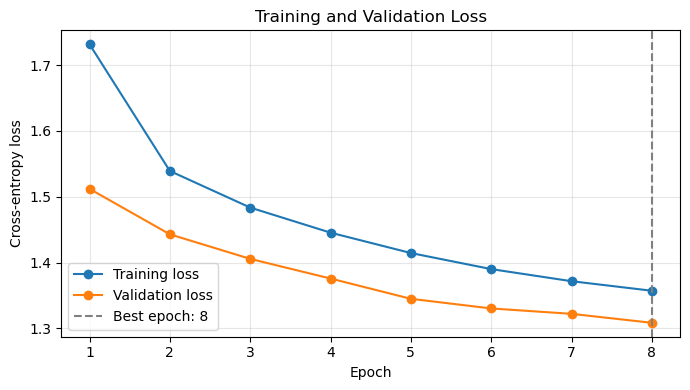

In [68]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(7, 4))

# training loss
plt.plot(epochs, history["train_loss"], marker="o", label="Training loss")
# validation loss
plt.plot(epochs, history["validation_loss"], marker="o", label="Validation loss")
# mark best epoch
plt.axvline(x=best_epoch, color="gray", linestyle="--", label=f"Best epoch: {best_epoch}")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training and Validation Loss")

plt.xticks(epochs)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

loss_curve_path = os.path.join(evaluation_directory, "training_validation_loss.png")
plt.savefig(loss_curve_path, dpi=300, bbox_inches="tight")

plt.show()
plt.close()

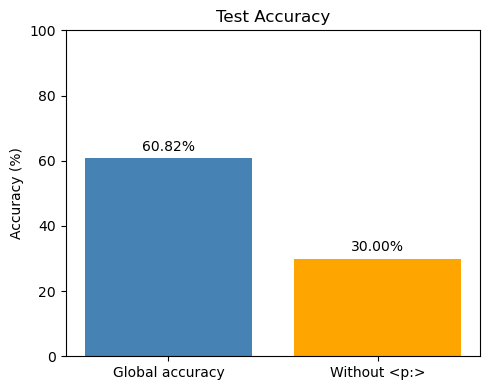

In [69]:
accuracy_names = ["Global accuracy", "Without <p:>"]

accuracy_values = [test_accuracy * 100, accuracy_without_pause * 100]

plt.figure(figsize=(5, 4))

bars = plt.bar(accuracy_names, accuracy_values, color=["steelblue", "orange"])

plt.ylabel("Accuracy (%)")
plt.title("Test Accuracy")
plt.ylim(0, 100)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()

plt.savefig(os.path.join(evaluation_directory, "test_accuracy_comparison.png"),
    dpi=300,
    bbox_inches="tight")

plt.show()
plt.close()

In [70]:
highest_recall_table = (phone_results_df.dropna(subset=["recall"]).nlargest(10, "recall")
    [[
        "phone",
        "true_sum",
        "recall",
        "precision"
    ]].copy())

highest_recall_table["recall"] *= 100
highest_recall_table["precision"] *= 100

highest_recall_table = highest_recall_table.rename(
    columns={
        "true_sum": "support",
        "recall": "recall (%)",
        "precision": "precision (%)"})

highest_recall_table = highest_recall_table.round(2)

display(highest_recall_table)

,phone,support,recall (%),precision (%)
3,<p:>,170279,99.21,83.91
33,n,18967,79.80,33.36
13,S,5144,75.08,68.74
37,s,9493,72.15,59.60
34,o:,3489,50.93,45.01
28,i:,6855,48.26,40.05
18,a:,7018,46.82,36.69
24,e:,7584,40.20,41.70
41,x,2547,37.89,37.78
20,aU,4424,37.77,27.11


In [71]:
directional_table = (directional_confusions_df.nlargest(10, "error_rate")
    [[
        "true_phone",
        "predicted_phone",
        "count",
        "true_phone_support",
        "error_rate"
    ]].copy())

directional_table = directional_table.rename(
    columns={
        "true_phone": "true",
        "predicted_phone": "predicted",
        "true_phone_support": "support",
        "error_rate": "error rate (%)"})

directional_table = directional_table.round(2)

display(directional_table)

,true,predicted,count,support,error rate (%)
1365,m,n,4558,6195,73.58
462,N,n,1486,2059,72.17
1465,p,<p:>,1580,2332,67.75
701,Z,S,71,110,64.55
175,?,<p:>,2583,4015,64.33
1843,z,s,2118,3345,63.32
1594,t,<p:>,10124,16503,61.35
1710,v,n,1622,2837,57.17
906,b,<p:>,1628,2980,54.63
87,9,6,287,594,48.32


In [72]:
phone_pair_table = (phone_pair_df.nlargest(10, "pair_confusion_rate")
    [[
        "phone_a",
        "phone_b",
        "a_as_b_rate",
        "b_as_a_rate",
        "pair_confusion_rate"
    ]].copy())

phone_pair_table = phone_pair_table.rename(
    columns={
        "phone_a": "phone A",
        "phone_b": "phone B",
        "a_as_b_rate": "A → B (%)",
        "b_as_a_rate": "B → A (%)",
        "pair_confusion_rate": "combined (%)"
    }
)

phone_pair_table = phone_pair_table.round(2)

display(phone_pair_table)

,phone A,phone B,A → B (%),B → A (%),combined (%)
837,m,n,73.58,3.66,20.87
578,a,a:,32.96,6.90,19.79
604,a:,aU,16.70,24.01,19.52
887,s,z,2.84,63.32,18.60
359,I,i:,23.57,3.19,13.33
515,U,o:,14.98,11.69,13.31
415,O,aU,29.32,3.55,12.51
716,e:,i:,15.99,7.53,11.97
226,@,n,28.71,1.81,11.75
59,6,aI,6.91,14.36,10.07
